# Baseline H1: consistencia histórica y modelos de conteo

Período **ALL** · Corners, Saques de banda y Faltas · evaluación secuencial prepartido.

Entrenamiento: **24/25**; validación: **25/26**; prueba final: **26/27**. Las ocho predictoras, su estandarización, los coeficientes, la media ingenua y la dispersión se ajustan solo en entrenamiento. El percentil 75 del CV se calcula sobre train antes de descartar los NaN específicos de cada mercado. El filtro segmenta la evaluación; no se reentrena un modelo diferente para los elegibles.

Se selecciona **un ganador por mercado por menor Brier Score macro en validación, segmento Todos**. Los empates se resuelven por nombre. No se usa test para seleccionar modelos ni recalibrar probabilidades. Las tres líneas de un partido no son observaciones independientes.

Fuente exclusiva: `database/oraculo.db`, conexión `mode=ro`, `query_only=ON`. No se imputa con ceros. Las ventanas pueden incorporar resultados ya conocidos de partidos anteriores dentro del mismo split.

In [1]:
from pathlib import Path
import hashlib
import platform
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

raiz = Path.cwd().resolve()
while not (raiz / "ml_models" / "h1" / "model.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError("Ejecutar dentro del proyecto Oraculo")
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from ml_models.h1.model import (
    ejecutar_baseline_h1, resumir_resultados_h1, preparar_mercado_h1,
    predictoras_h1, MERCADOS_H1, LINEAS_BINARIAS_H1,
)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
db = raiz / "database" / "oraculo.db"
def sha256(ruta):
    with ruta.open("rb") as archivo:
        return hashlib.file_digest(archivo, "sha256").hexdigest()
hash_antes = sha256(db)
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "SciPy": scipy.__version__,
       "matplotlib": matplotlib.__version__})
print("SHA-256 SQLite:", hash_antes)
resultado = ejecutar_baseline_h1(raiz=raiz)
resumen = resumir_resultados_h1(resultado.resultados)

{'Python': '3.13.2', 'NumPy': '2.5.1', 'pandas': '3.0.5', 'SciPy': '1.18.1', 'matplotlib': '3.11.2'}
SHA-256 SQLite: 9b2058bcbecc1a0b1bcc50c3675596e886b58e0c5f2f783d25986ff7819e987f


## Muestras y diagnóstico de entrenamiento

`N_antes` incluye todas las filas de la temporada. `N_validos` excluye únicamente NaN en las ocho entradas o el target del mercado; no descarta otras columnas ni aplica elegibilidad. Var/Mean usa varianza muestral (`ddof=1`) de train. Una razón mayor que uno describe sobredispersión **marginal**; alpha describe dispersión **condicional** a las predictoras.

In [2]:
display(resultado.muestras)
limites = pd.DataFrame([
    {"Split": s, "Temporada": getattr(resultado.particion, s).Temporada.iloc[0],
     "Desde_UTC": getattr(resultado.particion, s).Fecha_hora_utc.min(),
     "Hasta_UTC": getattr(resultado.particion, s).Fecha_hora_utc.max()}
    for s in ("train", "val", "test")
])
display(limites)
diagnostico = pd.DataFrame([
    {"Mercado": m, "Umbral_CV_train": resultado.particion.umbrales_cv[m],
     "Media_ingenua_train": resultado.modelos[m]["NaiveMedia"].media_,
     "Alpha_NB_train": resultado.modelos[m]["BinomialNegativa"].alpha_,
     "N_escalador_train": resultado.modelos[m]["Poisson"].escalador_.n_samples_seen_}
    for m in MERCADOS_H1
])
display(diagnostico)

,Temporada,Mercado,N_antes,N_validos,N_descartados_NaN,Media_train,Var_Mean_train
0,24/25,Corners,380,320,60,10.1375,1.2016
1,25/26,Corners,380,320,60,NaN,NaN
2,26/27,Corners,109,49,60,NaN,NaN
3,24/25,Saques_de_banda,380,320,60,32.7781,1.7929
4,25/26,Saques_de_banda,380,320,60,NaN,NaN
5,26/27,Saques_de_banda,109,49,60,NaN,NaN
6,24/25,Faltas,380,320,60,21.8000,1.2265
7,25/26,Faltas,380,320,60,NaN,NaN
8,26/27,Faltas,109,49,60,NaN,NaN


,Split,Temporada,Desde_UTC,Hasta_UTC
0,train,24/25,2024-08-16 19:00:00+00:00,2025-05-25 15:00:00+00:00
1,val,25/26,2025-08-15 19:00:00+00:00,2026-05-24 15:00:00+00:00
2,test,26/27,2026-08-21 19:00:00+00:00,2026-11-22 16:30:00+00:00


,Mercado,Umbral_CV_train,Media_ingenua_train,Alpha_NB_train,N_escalador_train
0,Corners,0.3555,10.1375,0.0147,320
1,Saques_de_banda,0.2370,32.7781,0.0128,320
2,Faltas,0.2465,21.8000,0.0036,320


## Comparación en validación (25/26)

Promedio macro de las tres líneas semienteras por mercado. N y cobertura corresponden a partidos únicos válidos, no a la suma de las líneas. MAE y RMSE se calculan sobre conteos; Accuracy usa `p >= 0.5`. Accuracy, tasa over, Log Loss y Brier son valores por observación (no porcentajes).

In [3]:
display(resumen.loc[resumen.Split.eq("val_25_26")].drop(columns="Split"))
validacion = resumen.loc[
    resumen.Split.eq("val_25_26") & resumen.Segmento.eq("Todos")
]
ganadores = (validacion.sort_values(["Mercado", "Brier_Score", "Modelo"])
             .drop_duplicates("Mercado")[["Mercado", "Modelo", "Brier_Score"]])
print("Ganadores fijados únicamente con validación:")
display(ganadores)
modelo_ganador = ganadores.set_index("Mercado").Modelo.to_dict()

,Mercado,Modelo,Segmento,N_partidos,Cobertura_pct,MAE_conteo,RMSE_conteo,Accuracy,Log_Loss,Brier_Score,Tasa_real_over
0,Corners,NaiveMedia,Todos,320,100.0000,2.6064,3.2253,0.6063,0.6634,0.2354,0.4354
1,Corners,NaiveMedia,Elegibles_H1,245,76.5625,2.5417,3.1514,0.6054,0.6640,0.2357,0.4449
2,Corners,NaiveMedia,No_elegibles_H1,75,23.4375,2.8178,3.4557,0.6089,0.6614,0.2344,0.4044
3,Corners,Poisson,Todos,320,100.0000,2.6133,3.2527,0.6063,0.6682,0.2375,0.4354
4,Corners,Poisson,Elegibles_H1,245,76.5625,2.5476,3.1854,0.6082,0.6684,0.2377,0.4449
5,Corners,Poisson,No_elegibles_H1,75,23.4375,2.8276,3.4636,0.6000,0.6673,0.2369,0.4044
6,Corners,BinomialNegativa,Todos,320,100.0000,2.6134,3.2528,0.6000,0.6671,0.2371,0.4354
7,Corners,BinomialNegativa,Elegibles_H1,245,76.5625,2.5478,3.1855,0.6014,0.6678,0.2374,0.4449
8,Corners,BinomialNegativa,No_elegibles_H1,75,23.4375,2.8275,3.4635,0.5956,0.6650,0.2360,0.4044
18,Saques_de_banda,NaiveMedia,Todos,320,100.0000,6.2440,7.7825,0.4750,0.7382,0.2714,0.5250


Ganadores fijados únicamente con validación:


,Mercado,Modelo,Brier_Score
0,Corners,NaiveMedia,0.2354
42,Faltas,BinomialNegativa,0.2352
24,Saques_de_banda,BinomialNegativa,0.2355


## Evaluación final en prueba (26/27)

La temporada 26/27 está incompleta en la instantánea. No se cambia la elección del modelo según estos resultados. La muestra válida de test es reducida y los segmentos no elegibles pueden contener pocos partidos.

In [4]:
display(resumen.loc[resumen.Split.eq("test_26_27")].drop(columns="Split"))

,Mercado,Modelo,Segmento,N_partidos,Cobertura_pct,MAE_conteo,RMSE_conteo,Accuracy,Log_Loss,Brier_Score,Tasa_real_over
9,Corners,NaiveMedia,Todos,49,100.0000,2.5467,3.4129,0.6395,0.6432,0.2257,0.3810
10,Corners,NaiveMedia,Elegibles_H1,35,71.4286,2.8068,3.7393,0.6381,0.6457,0.2269,0.3905
11,Corners,NaiveMedia,No_elegibles_H1,14,28.5714,1.8964,2.4108,0.6429,0.6370,0.2228,0.3571
12,Corners,Poisson,Todos,49,100.0000,2.4728,3.4326,0.6871,0.6240,0.2166,0.3810
13,Corners,Poisson,Elegibles_H1,35,71.4286,2.7946,3.7743,0.6476,0.6352,0.2225,0.3905
14,Corners,Poisson,No_elegibles_H1,14,28.5714,1.6684,2.3719,0.7857,0.5960,0.2019,0.3571
15,Corners,BinomialNegativa,Todos,49,100.0000,2.4727,3.4330,0.6803,0.6251,0.2171,0.3810
16,Corners,BinomialNegativa,Elegibles_H1,35,71.4286,2.7944,3.7747,0.6476,0.6359,0.2227,0.3905
17,Corners,BinomialNegativa,No_elegibles_H1,14,28.5714,1.6685,2.3724,0.7619,0.5981,0.2030,0.3571
27,Saques_de_banda,NaiveMedia,Todos,49,100.0000,6.0952,7.7424,0.5782,0.6808,0.2438,0.4218


## Tabla central H1: Todos frente a Elegibles_H1

El denominador de cobertura es el número de partidos válidos para el mercado en ese split. La comparación cambia el conjunto de partidos; describe rendimiento selectivo y no prueba un efecto causal del filtro. Menor Log Loss/Brier y mayor Accuracy indican mejor predicción.

In [5]:
contraste = resumen.loc[resumen.Segmento.isin(["Todos", "Elegibles_H1"])]
central = contraste.pivot(
    index=["Split", "Mercado", "Modelo"], columns="Segmento",
    values=["Accuracy", "Log_Loss", "Brier_Score", "Cobertura_pct"],
)
display(central)
seleccionados = contraste.merge(ganadores[["Mercado", "Modelo"]],
                               on=["Mercado", "Modelo"], validate="many_to_one")
pares = seleccionados.pivot(index=["Split", "Mercado", "Modelo"],
                           columns="Segmento",
                           values=["Accuracy", "Log_Loss", "Brier_Score",
                                   "N_partidos", "Cobertura_pct"])
deltas = pd.DataFrame({
    "Delta_Accuracy": pares["Accuracy"]["Elegibles_H1"] - pares["Accuracy"]["Todos"],
    "Delta_Log_Loss": pares["Log_Loss"]["Elegibles_H1"] - pares["Log_Loss"]["Todos"],
    "Delta_Brier": pares["Brier_Score"]["Elegibles_H1"] - pares["Brier_Score"]["Todos"],
    "Cobertura_elegibles_pct": pares["Cobertura_pct"]["Elegibles_H1"],
    "N_elegibles": pares["N_partidos"]["Elegibles_H1"],
})
print("Contraste de los ganadores elegidos en validación (elegibles menos todos):")
display(deltas)

Accuracy            Log_Loss  \
Segmento                                    Elegibles_H1  Todos Elegibles_H1   
Split      Mercado         Modelo                                              
test_26_27 Corners         BinomialNegativa       0.6476 0.6803       0.6359   
                           NaiveMedia             0.6381 0.6395       0.6457   
                           Poisson                0.6476 0.6871       0.6352   
           Faltas          BinomialNegativa       0.6124 0.6054       0.6870   
                           NaiveMedia             0.5271 0.5442       0.7342   
                           Poisson                0.6047 0.5986       0.6876   
           Saques_de_banda BinomialNegativa       0.7132 0.6939       0.5500   
                           NaiveMedia             0.5659 0.5782       0.6857   
                           Poisson                0.7132 0.6939       0.5448   
val_25_26  Corners         BinomialNegativa       0.6014 0.6000       0.6678   
                           NaiveMedia             0.6054 0.6063       0.6640   
                           Poisson                0.6082 0.6063       0.6684   
           Faltas          BinomialNegativa       0.5847 0.6083       0.6809   
                           NaiveMedia             0.5792 0.5854       0.6757   
                           Poisson                0.5847 0.6083       0.6822   
           Saques_de_banda BinomialNegativa       0.6298 0.6177       0.6622   
                           NaiveMedia             0.4631 0.4750       0.7448   
                           Poisson                0.6253 0.6135       0.6785   

                                                    Brier_Score         \
Segmento                                     Todos Elegibles_H1  Todos   
Split      Mercado         Modelo                                        
test_26_27 Corners         BinomialNegativa 0.6251       0.2227 0.2171   
                           NaiveMedia       0.6432       0.2269 0.2257   
                           Poisson          0.6240       0.2225 0.2166   
           Faltas          BinomialNegativa 0.6821       0.2446 0.2427   
                           NaiveMedia       0.7250       0.2699 0.2654   
                           Poisson          0.6828       0.2447 0.2428   
           Saques_de_banda BinomialNegativa 0.5625       0.1835 0.1896   
                           NaiveMedia       0.6808       0.2462 0.2438   
                           Poisson          0.5607       0.1814 0.1891   
val_25_26  Corners         BinomialNegativa 0.6671       0.2374 0.2371   
                           NaiveMedia       0.6634       0.2357 0.2354   
                           Poisson          0.6682       0.2377 0.2375   
           Faltas          BinomialNegativa 0.6639       0.2431 0.2352   
                           NaiveMedia       0.6692       0.2414 0.2382   
                           Poisson          0.6652       0.2436 0.2356   
           Saques_de_banda BinomialNegativa 0.6683       0.2324 0.2355   
                           NaiveMedia       0.7382       0.2746 0.2714   
                           Poisson          0.6858       0.2367 0.2404   

                                            Cobertura_pct           
Segmento                                     Elegibles_H1    Todos  
Split      Mercado         Modelo                                   
test_26_27 Corners         BinomialNegativa       71.4286 100.0000  
                           NaiveMedia             71.4286 100.0000  
                           Poisson                71.4286 100.0000  
           Faltas          BinomialNegativa       87.7551 100.0000  
                           NaiveMedia             87.7551 100.0000  
                           Poisson                87.7551 100.0000  
           Saques_de_banda BinomialNegativa       87.7551 100.0000  
                           NaiveMedia             87.7551 100.0000  
                           Poisson                87.

Contraste de los ganadores elegidos en validación (elegibles menos todos):


Delta_Accuracy  Delta_Log_Loss  \
Split      Mercado         Modelo                                             
test_26_27 Corners         NaiveMedia               -0.0014          0.0025   
           Faltas          BinomialNegativa          0.0070          0.0048   
           Saques_de_banda BinomialNegativa          0.0193         -0.0126   
val_25_26  Corners         NaiveMedia               -0.0008          0.0006   
           Faltas          BinomialNegativa         -0.0236          0.0170   
           Saques_de_banda BinomialNegativa          0.0120         -0.0061   

                                             Delta_Brier  \
Split      Mercado         Modelo                          
test_26_27 Corners         NaiveMedia             0.0012   
           Faltas          BinomialNegativa       0.0019   
           Saques_de_banda BinomialNegativa      -0.0061   
val_25_26  Corners         NaiveMedia             0.0003   
           Faltas          BinomialNegativa       0.0079   
           Saques_de_banda BinomialNegativa      -0.0031   

                                             Cobertura_elegibles_pct  \
Split      Mercado         Modelo                                      
test_26_27 Corners         NaiveMedia                        71.4286   
           Faltas          BinomialNegativa                  87.7551   
           Saques_de_banda BinomialNegativa                  87.7551   
val_25_26  Corners         NaiveMedia                        76.5625   
           Faltas          BinomialNegativa                  75.0000   
           Saques_de_banda BinomialNegativa                  93.1250   

                                             N_elegibles  
Split      Mercado         Modelo                         
test_26_27 Corners         NaiveMedia            35.0000  
           Faltas          BinomialNegativa      43.0000  
           Saques_de_banda BinomialNegativa      43.0000  
val_25_26  Corners         NaiveMedia           245.0000  
           Faltas          BinomialNegativa     240.0000  
           Saques_de_banda BinomialNegativa     298.0000

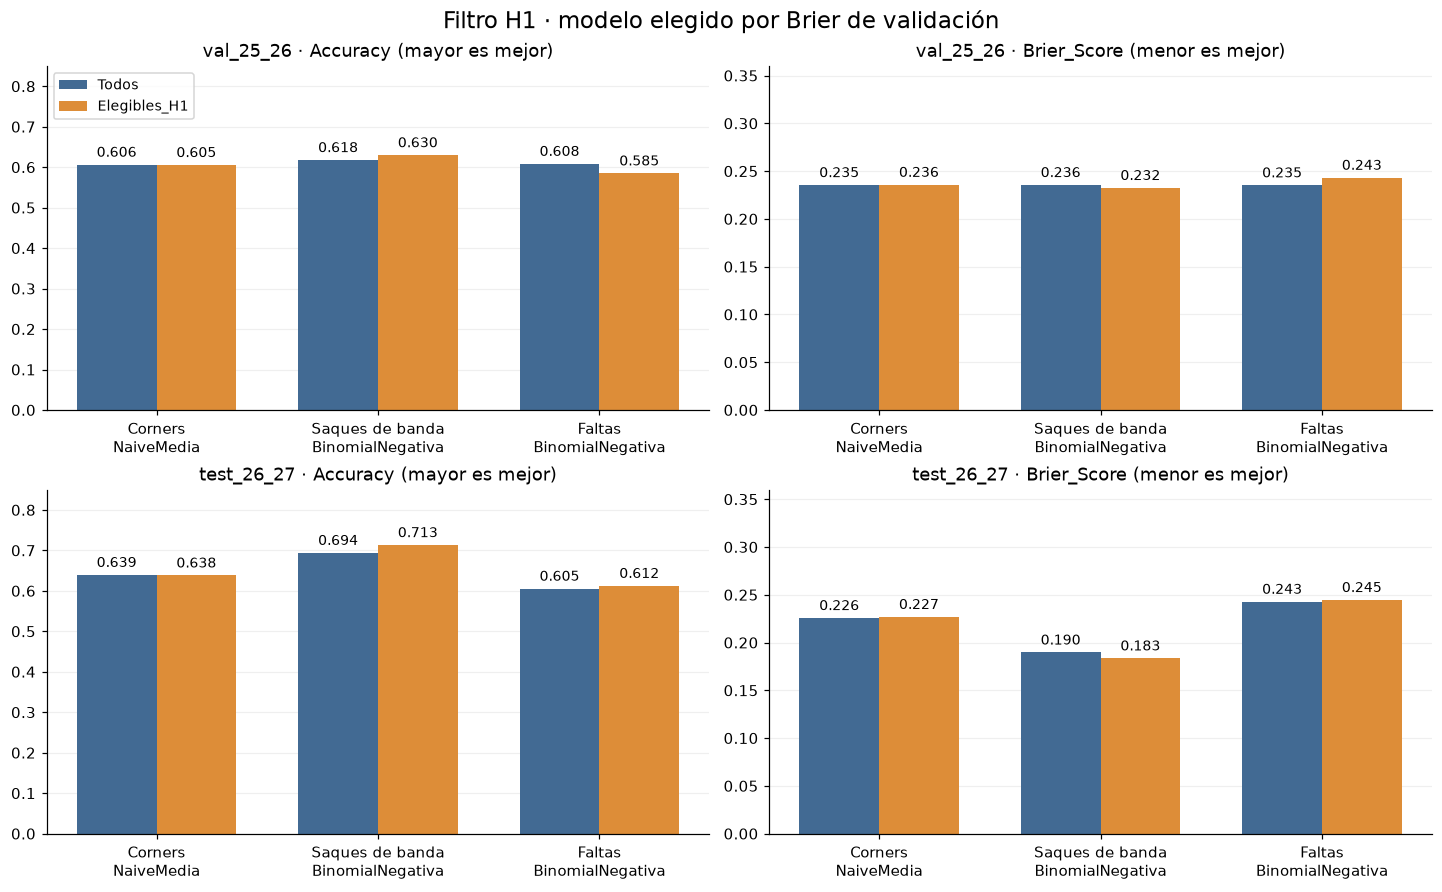

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
colores = {"Todos": "#426A93", "Elegibles_H1": "#DD8D38"}
nombres = [m.replace("_", " ") + "\n" + modelo_ganador[m] for m in MERCADOS_H1]
for fila, split in enumerate(("val_25_26", "test_26_27")):
    for col, metrica in enumerate(("Accuracy", "Brier_Score")):
        ax = axes[fila, col]
        for j, segmento in enumerate(("Todos", "Elegibles_H1")):
            bloque = seleccionados.loc[
                seleccionados.Split.eq(split) & seleccionados.Segmento.eq(segmento)
            ].set_index("Mercado").reindex(MERCADOS_H1)
            barras = ax.bar(np.arange(3) + (j - 0.5) * 0.36, bloque[metrica],
                            width=0.36, label=segmento, color=colores[segmento])
            ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=9)
        ax.set_xticks(np.arange(3), nombres)
        ax.set_ylim(0, 0.85 if metrica == "Accuracy" else 0.36)
        ax.set_title(f"{split} · {metrica} ({'mayor' if col == 0 else 'menor'} es mejor)")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        if fila == 0 and col == 0:
            ax.legend(loc="upper left", fontsize=9)
fig.suptitle("Filtro H1 · modelo elegido por Brier de validación", fontsize=15)
plt.show()

## Calibración de los ganadores

Línea central de cada mercado (10.5, 34.5 y 22.5). Diez intervalos fijos de probabilidad de ancho 0.1, excluyendo intervalos vacíos. Se muestran Todos y Elegibles_H1 tanto en validación como en test; **no se ajusta un calibrador**. Las etiquetas indican N por intervalo. Un modelo de media constante produce un único punto. La diagonal representa calibración ideal; las frecuencias con pocos partidos son inestables.

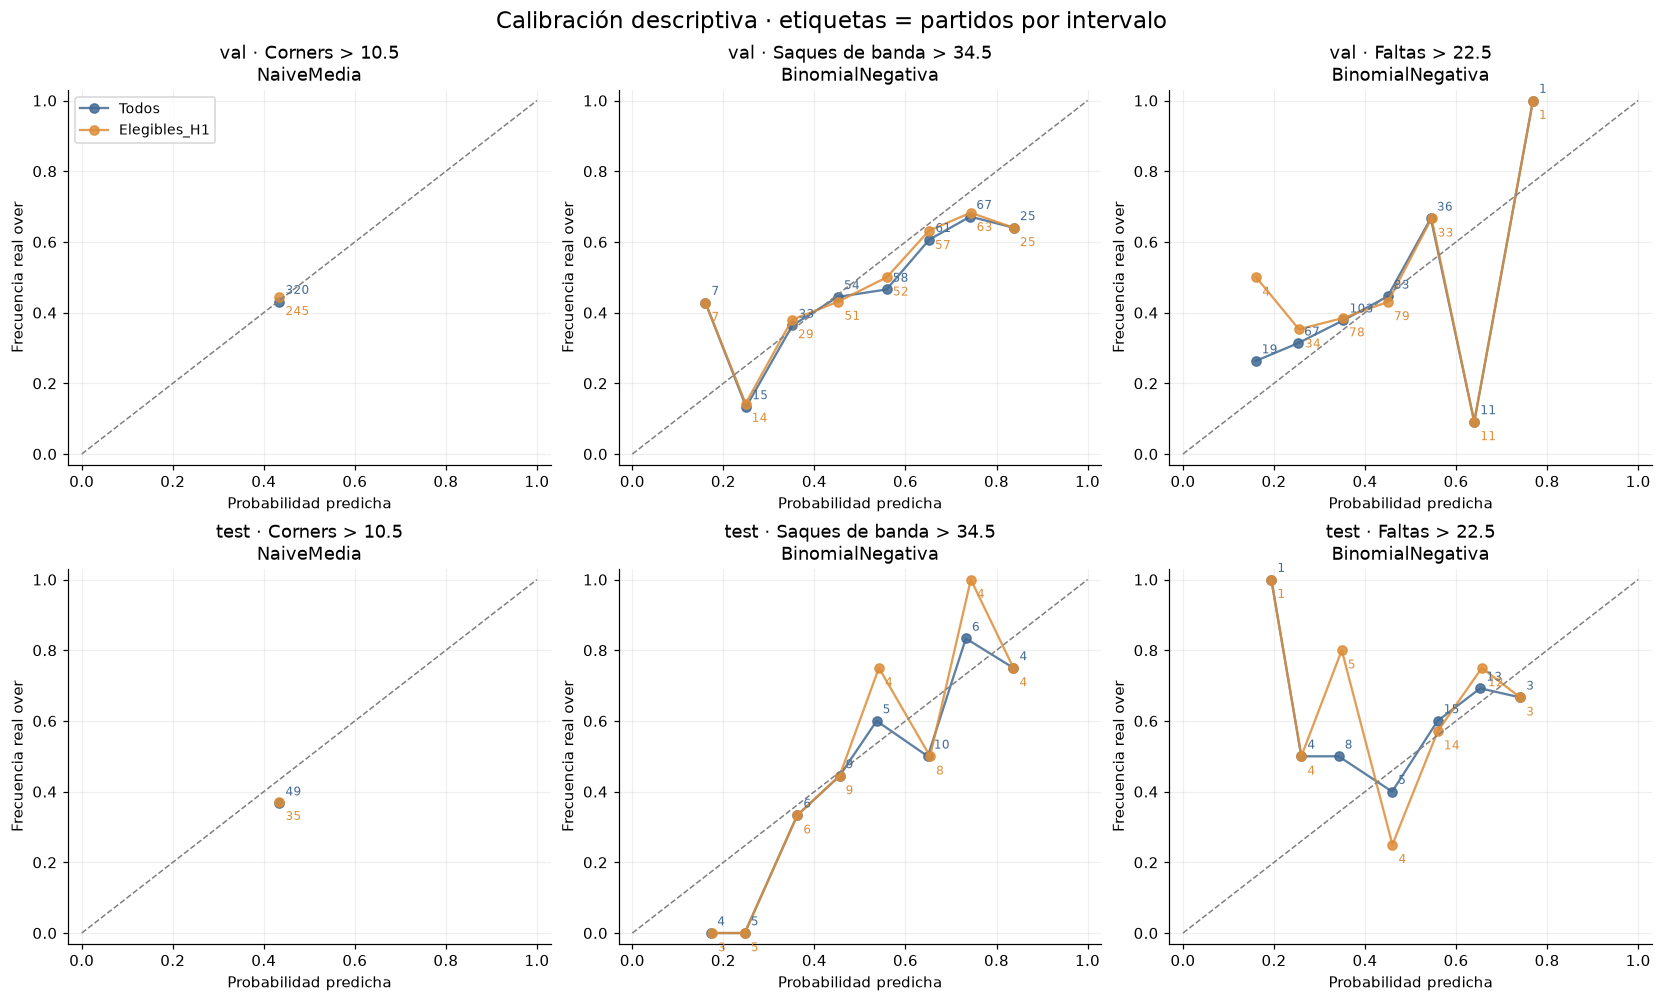

,Split,Mercado,Modelo,Linea,Segmento,Bin,Probabilidad,Frecuencia,N
0,val,Corners,NaiveMedia,10.5000,Todos,4,0.4342,0.4313,320
1,val,Corners,NaiveMedia,10.5000,Elegibles_H1,4,0.4342,0.4449,245
2,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,1,0.1604,0.4286,7
3,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,2,0.2499,0.1333,15
4,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,3,0.3515,0.3636,33
5,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,4,0.4515,0.4444,54
6,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,5,0.5584,0.4655,58
7,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,6,0.6523,0.6066,61
8,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,7,0.7422,0.6716,67
9,val,Saques_de_banda,BinomialNegativa,34.5000,Todos,8,0.8380,0.6400,25


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
filas_calibracion = []
for fila, split in enumerate(("val", "test")):
    for col, mercado in enumerate(MERCADOS_H1):
        ax = axes[fila, col]
        df = preparar_mercado_h1(getattr(resultado.particion, split), mercado)
        modelo = resultado.modelos[mercado][modelo_ganador[mercado]]
        linea = LINEAS_BINARIAS_H1[mercado][1]
        p = modelo.predict_proba_over(df[predictoras_h1(mercado)].to_numpy(), [linea])[:, 0]
        y = (df[f"target_{mercado}_total"].to_numpy() > linea).astype(float)
        for segmento in ("Todos", "Elegibles_H1"):
            mascara = (np.ones(len(df), dtype=bool) if segmento == "Todos"
                       else df[f"flag_elegible_h1_{mercado}"].to_numpy(dtype=bool))
            puntos = pd.DataFrame({"Probabilidad": p[mascara], "Real": y[mascara]})
            puntos["Bin"] = np.minimum((puntos.Probabilidad * 10).astype(int), 9)
            curva = puntos.groupby("Bin").agg(
                Probabilidad=("Probabilidad", "mean"), Frecuencia=("Real", "mean"),
                N=("Real", "size"),
            ).reset_index()
            for registro in curva.to_dict("records"):
                filas_calibracion.append({"Split": split, "Mercado": mercado,
                    "Modelo": modelo.nombre, "Linea": linea, "Segmento": segmento,
                    **registro})
            ax.plot(curva.Probabilidad, curva.Frecuencia, "o-", label=segmento,
                    color=colores[segmento], alpha=0.85)
            for r in curva.itertuples():
                ax.annotate(str(r.N), (r.Probabilidad, r.Frecuencia),
                            xytext=(4, 5 if segmento == "Todos" else -12),
                            textcoords="offset points", fontsize=8,
                            color=colores[segmento])
        ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
        ax.set(xlim=(-0.03, 1.03), ylim=(-0.03, 1.03),
               xlabel="Probabilidad predicha", ylabel="Frecuencia real over",
               title=f"{split} · {mercado.replace('_', ' ')} > {linea}\n{modelo.nombre}")
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=9)
fig.suptitle("Calibración descriptiva · etiquetas = partidos por intervalo", fontsize=15)
plt.show()
display(pd.DataFrame(filas_calibracion))

## Resultados por línea (sin agregación)

Se conservan las **162 filas**: 2 splits × 3 mercados × 3 modelos × 3 segmentos × 3 líneas. Cobertura suma 100% entre elegibles y no elegibles; Todos tiene 100%. Segmentos vacíos producirían métricas NaN, nunca ceros artificiales.

In [8]:
for split in ("val_25_26", "test_26_27"):
    print(split)
    display(resultado.resultados.loc[resultado.resultados.Split.eq(split)])

val_25_26


,Split,Mercado,Modelo,Segmento,Linea,N_partidos,Cobertura_pct,MAE_conteo,RMSE_conteo,Accuracy,Log_Loss,Brier_Score,Tasa_real_over
0,val_25_26,Corners,NaiveMedia,Todos,9.5000,320,100.0000,2.6064,3.2253,0.5625,0.6853,0.2461,0.5625
1,val_25_26,Corners,NaiveMedia,Todos,10.5000,320,100.0000,2.6064,3.2253,0.5687,0.6837,0.2453,0.4313
2,val_25_26,Corners,NaiveMedia,Todos,11.5000,320,100.0000,2.6064,3.2253,0.6875,0.6212,0.2149,0.3125
3,val_25_26,Corners,NaiveMedia,Elegibles_H1,9.5000,245,76.5625,2.5417,3.1514,0.5755,0.6822,0.2446,0.5755
4,val_25_26,Corners,NaiveMedia,Elegibles_H1,10.5000,245,76.5625,2.5417,3.1514,0.5551,0.6873,0.2471,0.4449
5,val_25_26,Corners,NaiveMedia,Elegibles_H1,11.5000,245,76.5625,2.5417,3.1514,0.6857,0.6225,0.2155,0.3143
6,val_25_26,Corners,NaiveMedia,No_elegibles_H1,9.5000,75,23.4375,2.8178,3.4557,0.5200,0.6954,0.2511,0.5200
7,val_25_26,Corners,NaiveMedia,No_elegibles_H1,10.5000,75,23.4375,2.8178,3.4557,0.6133,0.6719,0.2394,0.3867
8,val_25_26,Corners,NaiveMedia,No_elegibles_H1,11.5000,75,23.4375,2.8178,3.4557,0.6933,0.6168,0.2128,0.3067
9,val_25_26,Corners,Poisson,Todos,9.5000,320,100.0000,2.6133,3.2527,0.5563,0.6900,0.2485,0.5625


test_26_27


,Split,Mercado,Modelo,Segmento,Linea,N_partidos,Cobertura_pct,MAE_conteo,RMSE_conteo,Accuracy,Log_Loss,Brier_Score,Tasa_real_over
27,test_26_27,Corners,NaiveMedia,Todos,9.5000,49,100.0000,2.5467,3.4129,0.5306,0.6929,0.2499,0.5306
28,test_26_27,Corners,NaiveMedia,Todos,10.5000,49,100.0000,2.5467,3.4129,0.6327,0.6668,0.2369,0.3673
29,test_26_27,Corners,NaiveMedia,Todos,11.5000,49,100.0000,2.5467,3.4129,0.7551,0.5699,0.1904,0.2449
30,test_26_27,Corners,NaiveMedia,Elegibles_H1,9.5000,35,71.4286,2.8068,3.7393,0.5429,0.6900,0.2484,0.5429
31,test_26_27,Corners,NaiveMedia,Elegibles_H1,10.5000,35,71.4286,2.8068,3.7393,0.6286,0.6678,0.2374,0.3714
32,test_26_27,Corners,NaiveMedia,Elegibles_H1,11.5000,35,71.4286,2.8068,3.7393,0.7429,0.5792,0.1948,0.2571
33,test_26_27,Corners,NaiveMedia,No_elegibles_H1,9.5000,14,28.5714,1.8964,2.4108,0.5000,0.7002,0.2535,0.5000
34,test_26_27,Corners,NaiveMedia,No_elegibles_H1,10.5000,14,28.5714,1.8964,2.4108,0.6429,0.6640,0.2355,0.3571
35,test_26_27,Corners,NaiveMedia,No_elegibles_H1,11.5000,14,28.5714,1.8964,2.4108,0.7857,0.5467,0.1793,0.2143
36,test_26_27,Corners,Poisson,Todos,9.5000,49,100.0000,2.4728,3.4326,0.6327,0.6638,0.2358,0.5306


## Lectura de la evidencia y verificación de solo lectura

La instantánea permite evaluar la dirección y magnitud de los cambios, pero no confirma H1 de forma general. La elección por validación protege test frente a selección del modelo; no elimina la incertidumbre de una temporada parcial ni el cambio de distribución entre temporadas. El filtro puede mejorar Accuracy y empeorar simultáneamente Brier o Log Loss. No se interpretan las tres líneas correlacionadas como un aumento del tamaño de muestra.

In [9]:
for (split, mercado, modelo), fila in deltas.iterrows():
    print(f"{split} | {mercado} | {modelo}: "
          f"delta Accuracy={100*fila.Delta_Accuracy:+.2f} pp; "
          f"delta Brier={fila.Delta_Brier:+.4f}; "
          f"delta Log Loss={fila.Delta_Log_Loss:+.4f}; "
          f"cobertura={fila.Cobertura_elegibles_pct:.2f}% (N={int(fila.N_elegibles)})")
hash_despues = sha256(db)
assert hash_antes == hash_despues, "La base SQLite fue modificada"
assert len(resultado.resultados) == 162
print("SHA-256 antes = después:", hash_despues)
print("Pipeline finalizado; ninguna escritura sobre SQLite.")

test_26_27 | Corners | NaiveMedia: delta Accuracy=-0.14 pp; delta Brier=+0.0012; delta Log Loss=+0.0025; cobertura=71.43% (N=35)
test_26_27 | Faltas | BinomialNegativa: delta Accuracy=+0.70 pp; delta Brier=+0.0019; delta Log Loss=+0.0048; cobertura=87.76% (N=43)
test_26_27 | Saques_de_banda | BinomialNegativa: delta Accuracy=+1.93 pp; delta Brier=-0.0061; delta Log Loss=-0.0126; cobertura=87.76% (N=43)
val_25_26 | Corners | NaiveMedia: delta Accuracy=-0.08 pp; delta Brier=+0.0003; delta Log Loss=+0.0006; cobertura=76.56% (N=245)
val_25_26 | Faltas | BinomialNegativa: delta Accuracy=-2.36 pp; delta Brier=+0.0079; delta Log Loss=+0.0170; cobertura=75.00% (N=240)
val_25_26 | Saques_de_banda | BinomialNegativa: delta Accuracy=+1.20 pp; delta Brier=-0.0031; delta Log Loss=-0.0061; cobertura=93.12% (N=298)
SHA-256 antes = después: 9b2058bcbecc1a0b1bcc50c3675596e886b58e0c5f2f783d25986ff7819e987f
Pipeline finalizado; ninguna escritura sobre SQLite.
